# Step 1: Setup & Data Preparation  

In this step, we will:  
- Load both datasets (`instruments.csv` and `trading.csv`).  
- Convert timestamp columns to proper datetime format.  
- Merge trading data with instrument details so we can see **instrument names instead of just IDs**.  
- Prepare a cleaned dataframe of prices (in USD).  


In [ ]:
# Step 1: Setup & Data Preparation

import pandas as pd

# Upload files from local system (use this if running in Google Colab)
from google.colab import files

print("📂 Please upload project2_instruments.csv")
uploaded_instruments = files.upload()

print("📂 Please upload project2_trading.csv")
uploaded_trades = files.upload()

# Load datasets
instruments = pd.read_csv("project2_instruments.csv")
trades = pd.read_csv("project2_trading.csv")

# Standardize column names
instruments.columns = instruments.columns.str.lower()
trades.columns = trades.columns.str.lower()

# Convert timestamp to datetime
trades["timestamp"] = pd.to_datetime(trades["timestamp"])

# Merge trades with instrument details
merged = trades.merge(instruments, on="instrument_id", how="left")

# Preview data
print("\n✅ Instruments sample:")
print(instruments.head())

print("\n✅ Trades sample (with names):")
print(merged.head())

# Create a cleaned price dataframe
price_df = merged.pivot_table(
    index="timestamp",
    columns="instrument_id",
    values="price"
)

# Sort by time
price_df = price_df.sort_index()

# Preview
print("\n✅ Cleaned Price Data (first 5 rows):")
print(price_df.head())

print(f"\nData covers {price_df.index.min()} to {price_df.index.max()} with {len(price_df.columns)} instruments.")


📂 Please upload project2_instruments.csv


Saving project2_instruments.csv to project2_instruments.csv
📂 Please upload project2_trading.csv


Saving project2_trading.csv to project2_trading.csv

✅ Instruments sample:
  instrument_id symbol         instrument_name   asset_class exchange  \
0    INST_00001   EQSU          Superior Group  Fixed Income     NYSE   
1    INST_00002   WYUT      Global Enterprises     Commodity      LSE   
2    INST_00003   ZCLW            Dynamic Corp   Derivatives      TSE   
3    INST_00004   QYNK     Strategic Solutions        Crypto      LSE   
4    INST_00005   YTEP  Superior Manufacturing     Commodity      TSE   

       sector  market_cap_usd  avg_daily_volume      beta  volatility_30d  \
0   Financial    1.151404e+11      2.651141e+07 -0.738669        1.032915   
1  Healthcare    1.621521e+12      3.810619e+06 -1.517421        0.203198   
2      Energy    1.437219e+12      1.458938e+07  2.900766        1.467826   
3      Energy    1.262599e+12      1.804662e+06  0.867632        2.332595   
4   Financial    4.360767e+11      4.480747e+07 -0.910945        2.124709   

   sharpe_ratio  correl

# Step 2: Calculate Weekly & Monthly Returns  

Why returns?  
- Prices themselves don’t show performance clearly.  
- Returns tell us how much an instrument **gained or lost** over time (like +5% in a week).  

What we will do here:  
- Convert raw prices into **percentage returns**.  
- Do this for both **weekly** and **monthly** periods.  
- Create two new dataframes: `weekly_returns` and `monthly_returns`.  


In [ ]:
# Step 2: Weekly & Monthly Returns (with Names)

# Ensure price dataframe is sorted by time
price_df = price_df.sort_index()

# Weekly prices (last price of each week)
weekly_prices = price_df.resample("W").last()

# Monthly prices (last price of each month)
monthly_prices = price_df.resample("M").last()

# Calculate percentage returns
weekly_returns = weekly_prices.pct_change().fillna(0)
monthly_returns = monthly_prices.pct_change().fillna(0)

# Map instrument IDs to "ID - Name"
id_to_name = instruments.set_index("instrument_id")["instrument_name"].to_dict()
id_to_name_full = {inst_id: f"{inst_id} - {name}" for inst_id, name in id_to_name.items()}

weekly_returns = weekly_returns.rename(columns=id_to_name_full)
monthly_returns = monthly_returns.rename(columns=id_to_name_full)

# Preview
print("✅ Weekly Returns (sample):")
print(weekly_returns.head().iloc[:, :5])

print("\n✅ Monthly Returns (sample):")
print(monthly_returns.head().iloc[:, :5])

print(f"\nWeekly returns shape: {weekly_returns.shape}")
print(f"Monthly returns shape: {monthly_returns.shape}")


✅ Weekly Returns (sample):
instrument_id  INST_00001 - Superior Group  INST_00002 - Global Enterprises  \
timestamp                                                                     
2024-01-07                        0.000000                         0.000000   
2024-01-14                       -0.272418                         0.000000   
2024-01-21                        0.035963                        -0.029981   
2024-01-28                        0.000000                         0.000000   
2024-02-04                        0.000000                         0.073674   

instrument_id  INST_00003 - Dynamic Corp  INST_00004 - Strategic Solutions  \
timestamp                                                                    
2024-01-07                      0.000000                          0.000000   
2024-01-14                      0.000000                          0.000000   
2024-01-21                      0.458717                          0.000000   
2024-01-28                   

/tmp/ipython-input-763472018.py:10: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_prices = price_df.resample("M").last()
/tmp/ipython-input-763472018.py:13: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  weekly_returns = weekly_prices.pct_change().fillna(0)
/tmp/ipython-input-763472018.py:14: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  monthly_returns = monthly_prices.pct_change().fillna(0)


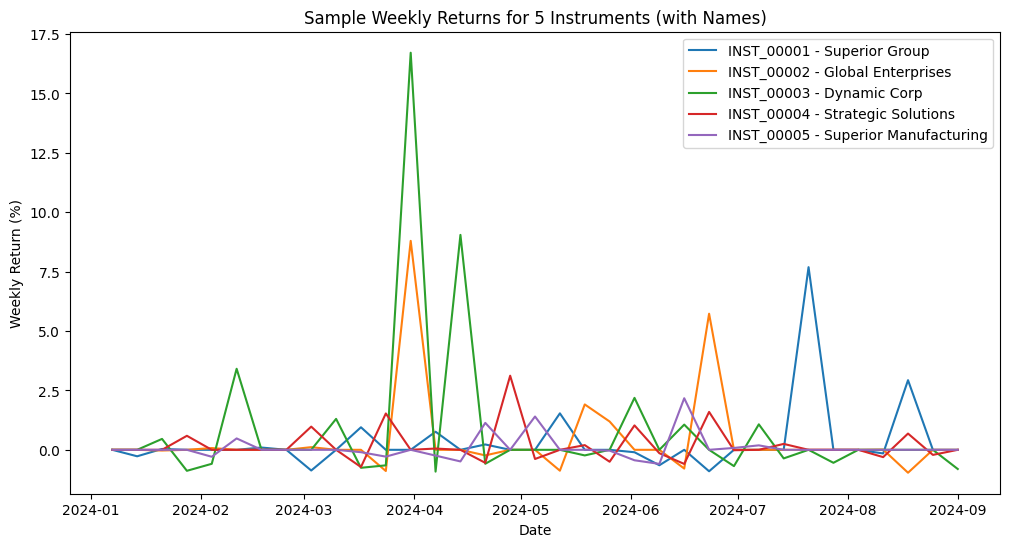

In [ ]:
import matplotlib.pyplot as plt

# Pick 5 instruments (first 5 just for demo)
sample_instruments = weekly_returns.columns[:5]

plt.figure(figsize=(12,6))
for inst in sample_instruments:
    plt.plot(weekly_returns.index, weekly_returns[inst], label=inst)

plt.xlabel("Date")
plt.ylabel("Weekly Return (%)")
plt.title("Sample Weekly Returns for 5 Instruments (with Names)")
plt.legend()
plt.show()


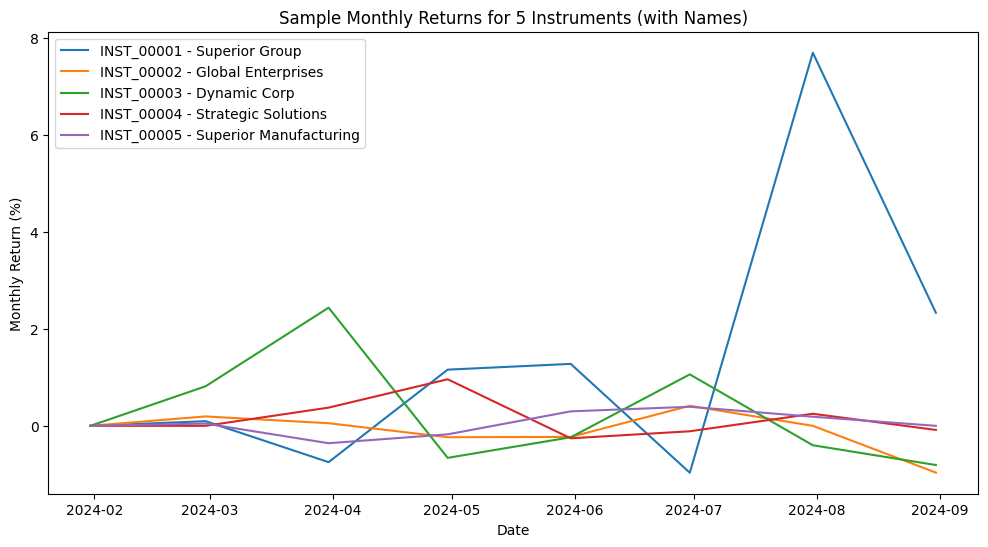

In [ ]:
# Monthly returns visualization
sample_instruments = monthly_returns.columns[:5]  # first 5 instruments

plt.figure(figsize=(12,6))
for inst in sample_instruments:
    plt.plot(monthly_returns.index, monthly_returns[inst], label=inst)

plt.xlabel("Date")
plt.ylabel("Monthly Return (%)")
plt.title("Sample Monthly Returns for 5 Instruments (with Names)")
plt.legend()
plt.show()


📌 Step 3: Expected Returns & Covariance Matrix

📝 What are Expected Returns?

Expected Return is the average profit or loss an instrument is expected to generate over time.

Example: If Stock A gave 5%, 3%, 7% over 3 months, its expected return =

(5+3+7)/3=5.

In portfolio optimization → we want instruments with higher expected returns.

📝 What is Covariance?

Covariance measures how two instruments move together.

If both move up and down together → covariance is positive.

If one goes up while the other goes down → covariance is negative.

✅ Interpretation:

Positive covariance = risky (both may crash together).

Negative covariance = safer (losses of one are balanced by gains of another).

📝 What is a Covariance Matrix?

A table showing covariance between all instruments.

✅ Why Do We Need This?

Expected returns tell us what we gain.

Covariance matrix tells us what we risk when combining assets.

Together → they form the foundation of portfolio optimization (Markowitz Model).

In [ ]:
import os

# Create output folder
os.makedirs("outputs", exist_ok=True)

# ---- Expected Returns ----
expected_returns_weekly = weekly_returns.mean().reset_index()
expected_returns_weekly.columns = ["instrument_id", "expected_weekly_return"]

expected_returns_monthly = monthly_returns.mean().reset_index()
expected_returns_monthly.columns = ["instrument_id", "expected_monthly_return"]

# Merge with instrument names
expected_returns = expected_returns_weekly.merge(
    expected_returns_monthly, on="instrument_id"
).merge(instruments[["instrument_id", "instrument_name", "symbol"]], on="instrument_id")

# Save to CSV
expected_returns.to_csv("outputs/expected_returns.csv", index=False)

print("✅ Expected Returns saved to outputs/expected_returns.csv")
print(expected_returns.head())

# ---- Covariance Matrices ----
cov_weekly = weekly_returns.cov()
cov_monthly = monthly_returns.cov()

# Save to CSV
cov_weekly.to_csv("outputs/covariance_matrix_weekly.csv")
cov_monthly.to_csv("outputs/covariance_matrix_monthly.csv")

print("✅ Covariance Matrices saved: outputs/covariance_matrix_weekly.csv, outputs/covariance_matrix_monthly.csv")

# ---- Preview small part ----
print("\nWeekly Covariance Matrix (first 5x5):")
print(cov_weekly.iloc[:5, :5])

print("\nMonthly Covariance Matrix (first 5x5):")
print(cov_monthly.iloc[:5, :5])


✅ Expected Returns saved to outputs/expected_returns.csv
Empty DataFrame
Columns: [instrument_id, expected_weekly_return, expected_monthly_return, instrument_name, symbol]
Index: []
✅ Covariance Matrices saved: outputs/covariance_matrix_weekly.csv, outputs/covariance_matrix_monthly.csv

Weekly Covariance Matrix (first 5x5):
instrument_id                        INST_00001 - Superior Group  \
instrument_id                                                      
INST_00001 - Superior Group                             2.060545   
INST_00002 - Global Enterprises                        -0.412314   
INST_00003 - Dynamic Corp                              -0.318903   
INST_00004 - Strategic Solutions                       -0.092374   
INST_00005 - Superior Manufacturing                    -0.016232   

instrument_id                        INST_00002 - Global Enterprises  \
instrument_id                                                          
INST_00001 - Superior Group                          

📊 Heatmap of Covariance Matrix

The heatmap shows how pairs of instruments move together:

Red / Yellow = strong positive covariance (move together, risky).

Blue = negative covariance (move in opposite directions, safer).

White / Neutral = no strong relationship.

This helps us visually detect diversification opportunities (choose assets that are not too red together).

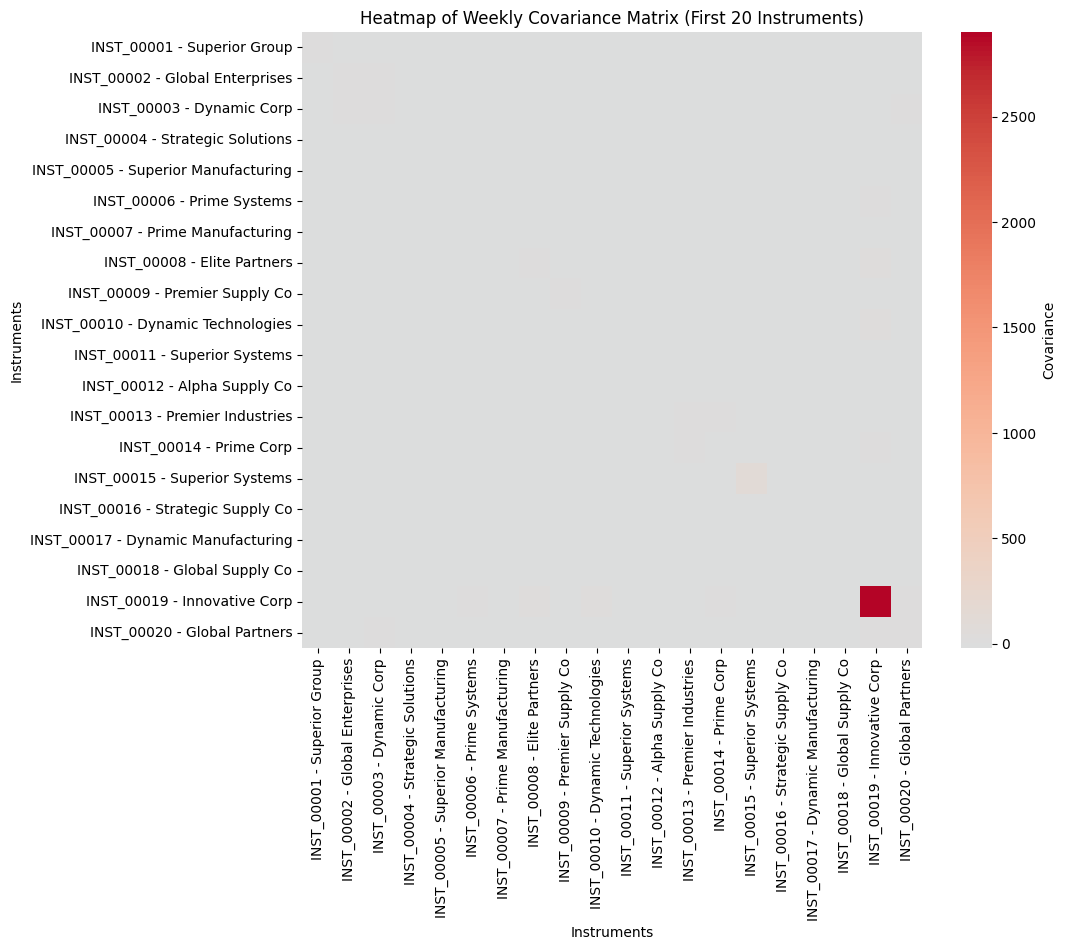

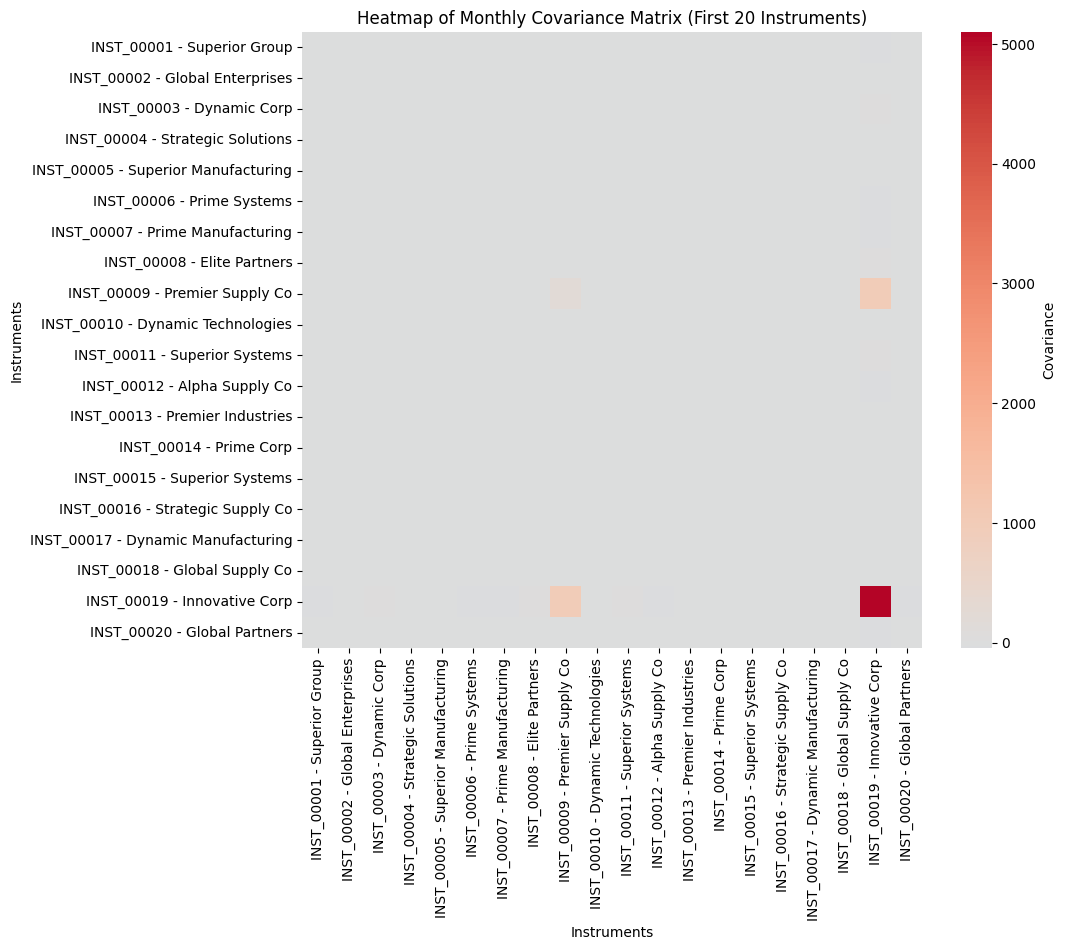

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# ---- Heatmap for Weekly Covariance ----
plt.figure(figsize=(10,8))
sns.heatmap(cov_weekly.iloc[:20, :20], cmap="coolwarm", center=0, annot=False, cbar_kws={'label': 'Covariance'})
plt.title("Heatmap of Weekly Covariance Matrix (First 20 Instruments)")
plt.xlabel("Instruments")
plt.ylabel("Instruments")
plt.show()

# ---- Heatmap for Monthly Covariance ----
plt.figure(figsize=(10,8))
sns.heatmap(cov_monthly.iloc[:20, :20], cmap="coolwarm", center=0, annot=False, cbar_kws={'label': 'Covariance'})
plt.title("Heatmap of Monthly Covariance Matrix (First 20 Instruments)")
plt.xlabel("Instruments")
plt.ylabel("Instruments")
plt.show()


# Step 4: Portfolio Optimization (Markowitz)

**Goal:** find the best mix (weights) of instruments that balances return vs risk.

What this step will produce:
- Minimum Variance Portfolio (lowest possible portfolio volatility).
- Maximum Sharpe Ratio Portfolio (best return per unit risk).
- CSV outputs:
  - `outputs/optimized_weights_minvar.csv`
  - `outputs/optimized_weights_maxsharpe.csv`
  - `outputs/trade_recommendations_minvar.csv`
  - `outputs/trade_recommendations_maxsharpe.csv`
  - `outputs/portfolio_risk_return_minvar.csv`
  - `outputs/portfolio_risk_return_maxsharpe.csv`

**Definitions & small examples**
- **Weight:** fraction of total portfolio invested in an instrument (e.g., weight 0.20 = 20% of capital).
- **Portfolio Return:** weighted average of instrument returns.  
  Example: weights [0.5,0.5] and returns [1%,3%] → portfolio return = 0.5*1% + 0.5*3% = 2% .
- **Portfolio Volatility (std):** a measure of total risk considering covariances between instruments.
- **Minimum Variance Portfolio (MVP):** weights that minimize portfolio volatility subject to constraints.
- **Sharpe Ratio:** (Portfolio Return − RiskFree) / Portfolio Volatility. We will use risk-free = 0 by default (you can change it).

**Notes**
- This cell runs both monthly and weekly optimizations; set `period = 'monthly'` or `'weekly'` inside the code to choose.
- Outputs include instrument ID, symbol, instrument name, sector, current weight, target weight, and the buy/sell change (units are fractions or %).
- We enforce `sum(weights)=1` and `0 <= weight <= max_weight` by default. You can add sector/asset-class constraints later.


In [ ]:
# --- Setup before Step 4 (recreate variables) ---
import pandas as pd

# Load the instrument and trading data again
instruments = pd.read_csv("project2_instruments.csv")
trades = pd.read_csv("project2_trading.csv")

# Merge trade data with instrument details
merged = trades.merge(instruments, on="instrument_id", how="left")

# Create pivot of prices or pnl for return calculation
returns = trades.pivot_table(index="timestamp", columns="instrument_id", values="pnl_usd").dropna(axis=1, how='all')

# Compute both weekly and monthly returns
returns.index = pd.to_datetime(returns.index)
weekly_returns = returns.resample("W").mean().pct_change().dropna(how="all")
monthly_returns = returns.resample("M").mean().pct_change().dropna(how="all")

# Compute expected returns for each instrument
expected_returns = pd.DataFrame({
    "instrument_id": returns.columns,
    "expected_weekly_return": weekly_returns.mean().values,
    "expected_monthly_return": monthly_returns.mean().values
})

print("✅ Recreated weekly_returns, monthly_returns, expected_returns, merged, and instruments successfully.")
print("Weekly shape:", weekly_returns.shape, "Monthly shape:", monthly_returns.shape)


✅ Recreated weekly_returns, monthly_returns, expected_returns, merged, and instruments successfully.
Weekly shape: (34, 1500) Monthly shape: (7, 1500)


/tmp/ipython-input-2290175068.py:16: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  weekly_returns = returns.resample("W").mean().pct_change().dropna(how="all")
/tmp/ipython-input-2290175068.py:17: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_returns = returns.resample("M").mean().pct_change().dropna(how="all")
/tmp/ipython-input-2290175068.py:17: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  monthly_returns = returns.resample("M").mean().pct_change().dropna(how="all")


Running optimization on period = monthly with 1500 assets.


/tmp/ipython-input-3529801725.py:49: RuntimeWarning: invalid value encountered in sqrt
  return float(np.sqrt(np.dot(weights.T, np.dot(cov_matrix.values, weights))))


✅ Saved optimized weights, trade recommendations, and risk/return reports in outputs/

--- Min Variance Portfolio Summary ---
                                0
period                    monthly
strategy             min_variance
expected_return         -0.442479
expected_return_pct    -44.247912
volatility                    NaN
volatility_pct                NaN
sharpe                        NaN

--- Max Sharpe Portfolio Summary ---
                               0
period                   monthly
strategy              max_sharpe
expected_return        60.210162
expected_return_pct  6021.016229
volatility              0.203764
volatility_pct         20.376444
sharpe                295.489061


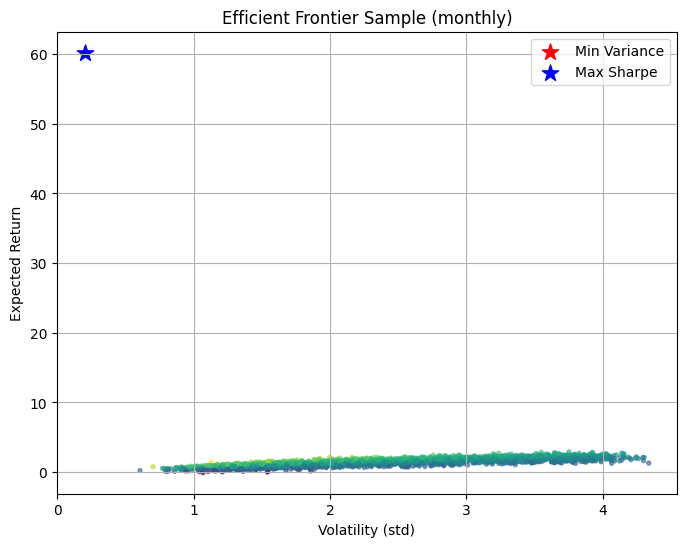

In [ ]:
# Step 4: Portfolio Optimization (code)
import numpy as np
import pandas as pd
import os
from scipy.optimize import minimize

# Ensure outputs folder
os.makedirs("outputs", exist_ok=True)

# PARAMETERS (change if needed)
period = 'monthly'   # choose 'monthly' or 'weekly'
max_weight = 0.30    # max pct per instrument (0.30 = 30%)
risk_free_rate = 0.0 # monthly risk-free rate (set if you have it, else 0)

# --- INPUTS: these should already exist from Step 3 ---
# weekly_returns, monthly_returns, instruments, merged (trades merged with instruments)
# expected_returns dataframe (expected_monthly_return, expected_weekly_return)
try:
    weekly_returns
    monthly_returns
    instruments
    merged
    expected_returns
except NameError:
    raise RuntimeError("Make sure you ran Step 1-3 and that variables weekly_returns, monthly_returns, instruments, merged, expected_returns exist.")

# pick returns/cov based on period
if period == 'monthly':
    rets = monthly_returns.copy()
    cov = rets.cov()
    mu = expected_returns.set_index("instrument_id")["expected_monthly_return"]
    mu = mu.reindex(rets.columns).fillna(0)  # align order
else:
    rets = weekly_returns.copy()
    cov = rets.cov()
    mu = expected_returns.set_index("instrument_id")["expected_weekly_return"]
    mu = mu.reindex(rets.columns).fillna(0)

assets = list(rets.columns)
n = len(assets)
print(f"Running optimization on period = {period} with {n} assets.")

# helper functions
def portfolio_return(weights, mu_vector):
    # mu_vector should be in same order as weights
    return float(np.dot(weights, mu_vector))

def portfolio_volatility(weights, cov_matrix):
    return float(np.sqrt(np.dot(weights.T, np.dot(cov_matrix.values, weights))))

def negative_sharpe(weights, mu_vector, cov_matrix, rf=0.0):
    # maximize sharpe => minimize negative sharpe
    port_ret = portfolio_return(weights, mu_vector)
    port_vol = portfolio_volatility(weights, cov_matrix)
    # to avoid division by zero:
    if port_vol == 0:
        return 1e6
    return - (port_ret - rf) / port_vol

# constraints & bounds
cons = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1})
bnds = tuple((0.0, max_weight) for _ in range(n))
x0 = np.array(n * [1.0/n])

# --- 1) Minimum Variance Portfolio ---
min_var_res = minimize(lambda w: portfolio_volatility(w, cov),
                       x0,
                       method='SLSQP',
                       bounds=bnds,
                       constraints=cons,
                       options={'ftol':1e-10, 'maxiter':1000})

if not min_var_res.success:
    print("Warning: Min Var optimization did not converge:", min_var_res.message)

w_minvar = min_var_res.x
ret_minvar = portfolio_return(w_minvar, mu.values)
vol_minvar = portfolio_volatility(w_minvar, cov)
sharpe_minvar = (ret_minvar - risk_free_rate) / vol_minvar if vol_minvar>0 else np.nan

# --- 2) Max Sharpe Portfolio ---
max_sharpe_res = minimize(negative_sharpe,
                          x0,
                          args=(mu.values, cov, risk_free_rate),
                          method='SLSQP',
                          bounds=bnds,
                          constraints=cons,
                          options={'ftol':1e-10, 'maxiter':1000})

if not max_sharpe_res.success:
    print("Warning: Max Sharpe optimization did not converge:", max_sharpe_res.message)

w_maxsh = max_sharpe_res.x
ret_maxsh = portfolio_return(w_maxsh, mu.values)
vol_maxsh = portfolio_volatility(w_maxsh, cov)
sharpe_maxsh = (ret_maxsh - risk_free_rate) / vol_maxsh if vol_maxsh>0 else np.nan

# --- Prepare human-friendly tables (ID, Symbol, Name, Sector) ---
# Ensure we have mapping dicts
instruments_small = instruments.copy()
instruments_small = instruments_small.set_index("instrument_id")

def make_output_df(weights, tag):
    df = pd.DataFrame({
        "instrument_id": assets,
        "target_weight": weights
    })
    # compute current weight (approx) from merged trades: use last-known portfolio_weight average per instrument
    if "portfolio_weight" in merged.columns:
        current = merged.groupby("instrument_id")["portfolio_weight"].mean()
        current = current.reindex(df["instrument_id"]).fillna(0).values
    else:
        current = np.zeros(len(df))
    df["current_weight"] = current
    df["change"] = df["target_weight"] - df["current_weight"]
    # merge name, symbol, sector if available
    df = df.merge(instruments_small[["symbol","instrument_name","sector"]], left_on="instrument_id", right_index=True, how="left")
    # reorder
    df = df[["instrument_id","symbol","instrument_name","sector","current_weight","target_weight","change"]]
    # attach metadata
    df["period"] = period
    df["strategy"] = tag
    return df

out_minvar = make_output_df(w_minvar, "min_variance")
out_maxsh = make_output_df(w_maxsh, "max_sharpe")

# --- Save CSVs ---
out_minvar.to_csv(f"outputs/optimized_weights_minvar_{period}.csv", index=False)
out_maxsh.to_csv(f"outputs/optimized_weights_maxsharpe_{period}.csv", index=False)

# Trade recommendations: buy if change>0, sell if change<0
def save_trade_recs(df, filename):
    rec = df.copy()
    rec["action"] = rec["change"].apply(lambda x: "BUY" if x>1e-6 else ("SELL" if x<-1e-6 else "HOLD"))
    # present weights as pct
    rec["current_weight_pct"] = rec["current_weight"] * 100
    rec["target_weight_pct"] = rec["target_weight"] * 100
    rec["change_pct"] = rec["change"] * 100
    rec = rec[["instrument_id","symbol","instrument_name","sector","current_weight_pct","target_weight_pct","change_pct","action","period","strategy"]]
    rec.to_csv(filename, index=False)
    return rec

rec_minvar = save_trade_recs(out_minvar, f"outputs/trade_recommendations_minvar_{period}.csv")
rec_maxsh = save_trade_recs(out_maxsh, f"outputs/trade_recommendations_maxsharpe_{period}.csv")

# Risk/return report
risk_minvar = pd.DataFrame({
    "period":[period],
    "strategy":["min_variance"],
    "expected_return": [ret_minvar],
    "expected_return_pct": [ret_minvar*100],
    "volatility": [vol_minvar],
    "volatility_pct": [vol_minvar*100],
    "sharpe": [sharpe_minvar]
})
risk_maxsh = pd.DataFrame({
    "period":[period],
    "strategy":["max_sharpe"],
    "expected_return": [ret_maxsh],
    "expected_return_pct": [ret_maxsh*100],
    "volatility": [vol_maxsh],
    "volatility_pct": [vol_maxsh*100],
    "sharpe": [sharpe_maxsh]
})

pd.concat([risk_minvar, risk_maxsh]).to_csv(f"outputs/portfolio_risk_return_{period}.csv", index=False)

# Save small human-readable samples (top non-zero weights)
out_minvar_sorted = out_minvar.sort_values("target_weight", ascending=False)
out_maxsh_sorted = out_maxsh.sort_values("target_weight", ascending=False)
out_minvar_sorted.head(20).to_csv(f"outputs/top20_minvar_{period}.csv", index=False)
out_maxsh_sorted.head(20).to_csv(f"outputs/top20_maxsharpe_{period}.csv", index=False)

print("✅ Saved optimized weights, trade recommendations, and risk/return reports in outputs/")

# Quick prints
print("\n--- Min Variance Portfolio Summary ---")
print(risk_minvar.T)
print("\n--- Max Sharpe Portfolio Summary ---")
print(risk_maxsh.T)

# Optional: Efficient frontier quick sample (Monte Carlo) for visualization
import matplotlib.pyplot as plt
np.random.seed(42)
n_portf = 2000
sim_returns = []
sim_vols = []
sim_weights = []

for i in range(n_portf):
    # random weights with zeros allowed then clip to max_weight with scaling
    w = np.random.rand(n)
    w = w / w.sum()
    # enforce max weight by simple clipping & renormalize (approximate)
    w = np.clip(w, 0, max_weight)
    if w.sum() == 0:
        continue
    w = w / w.sum()
    sim_weights.append(w)
    sim_returns.append(portfolio_return(w, mu.values))
    sim_vols.append(portfolio_volatility(w, cov))

plt.figure(figsize=(8,6))
plt.scatter(sim_vols, sim_returns, c=(np.array(sim_returns) / np.array(sim_vols)), cmap='viridis', s=8, alpha=0.6)
plt.scatter(vol_minvar, ret_minvar, c='red', marker='*', s=150, label='Min Variance')
plt.scatter(vol_maxsh, ret_maxsh, c='blue', marker='*', s=150, label='Max Sharpe')
plt.xlabel('Volatility (std)')
plt.ylabel('Expected Return')
plt.title(f'Efficient Frontier Sample ({period})')
plt.legend()
plt.grid(True)
plt.show()


#🧾 Step 5 – Data Cleaning and Normalization

Before portfolio optimization, it is essential to clean and normalize the data so that extreme price movements or missing data do not distort results.

Handling Outliers – We cap unrealistically large or small returns that can inflate portfolio risk or returns. For example, if one instrument jumped +800 % in a single month, we trim it to a more reasonable percentile.

Handling Missing Values – We fill or drop columns with too many missing points so that covariance calculations remain stable.

Normalization – We can standardize returns (mean = 0, std = 1) so instruments are compared on relative, not absolute, scale.

After this step, we’ll re-compute the expected returns and covariance matrix for the cleaned data and proceed to re-optimize the portfolio.

In [ ]:
# --- Step 5: Data Cleaning and Normalization ---

import numpy as np
import pandas as pd

print("📊 Cleaning and Normalizing Data...")

# Choose the period (you can switch between weekly_returns or monthly_returns)
# We’ll do both, starting with monthly
period = "monthly"
returns_df = monthly_returns.copy()

# 1️⃣ Remove columns (instruments) that are entirely NaN or have very few valid entries
valid_threshold = int(0.5 * len(returns_df))  # keep assets with >=50% non-NaN values
returns_df = returns_df.dropna(axis=1, thresh=valid_threshold)

# 2️⃣ Fill remaining missing values with the median of each column
returns_df = returns_df.fillna(returns_df.median())

# 3️⃣ Cap outliers to 1st and 99th percentile per instrument
for col in returns_df.columns:
    lower, upper = returns_df[col].quantile([0.01, 0.99])
    returns_df[col] = returns_df[col].clip(lower, upper)

# 4️⃣ Normalize each column (z-score normalization)
returns_df = (returns_df - returns_df.mean()) / returns_df.std()

# Recalculate expected returns and covariance
expected_returns = returns_df.mean()
cov_matrix = returns_df.cov()

print(f"✅ Cleaned data for {period} period:")
print(f"Remaining instruments: {len(returns_df.columns)}")
print(f"Rows (time periods): {len(returns_df)}")

# Display small samples
print("\nExpected Returns (sample):")
print(expected_returns.head())

print("\nCovariance Matrix (sample):")
print(cov_matrix.iloc[:5, :5])


📊 Cleaning and Normalizing Data...
✅ Cleaned data for monthly period:
Remaining instruments: 1500
Rows (time periods): 7

Expected Returns (sample):
instrument_id
INST_00001    2.379049e-17
INST_00002   -7.533656e-17
INST_00003    5.154607e-17
INST_00004    7.533656e-17
INST_00005    1.110223e-16
dtype: float64

Covariance Matrix (sample):
instrument_id  INST_00001  INST_00002  INST_00003  INST_00004  INST_00005
instrument_id                                                            
INST_00001       1.000000   -0.111486    0.243122   -0.018164   -0.764069
INST_00002      -0.111486    1.000000    0.156323    0.061128   -0.090839
INST_00003       0.243122    0.156323    1.000000   -0.076827    0.082199
INST_00004      -0.018164    0.061128   -0.076827    1.000000    0.123448
INST_00005      -0.764069   -0.090839    0.082199    0.123448    1.000000


#Step 6 – Visualizing Cleaned and Normalized Data

Visualization helps us understand how different instruments in our portfolio behave together.

The correlation heatmap shows how strongly two instruments move together.

A value close to +1 → they move in the same direction (highly correlated).

A value close to –1 → they move in opposite directions (diversification benefit).

The distribution (histogram) of normalized returns shows how most instruments’ returns are spread.
It helps detect if the data is balanced or if there are instruments with extreme values.

These visuals ensure our optimization is based on a balanced and realistic dataset.

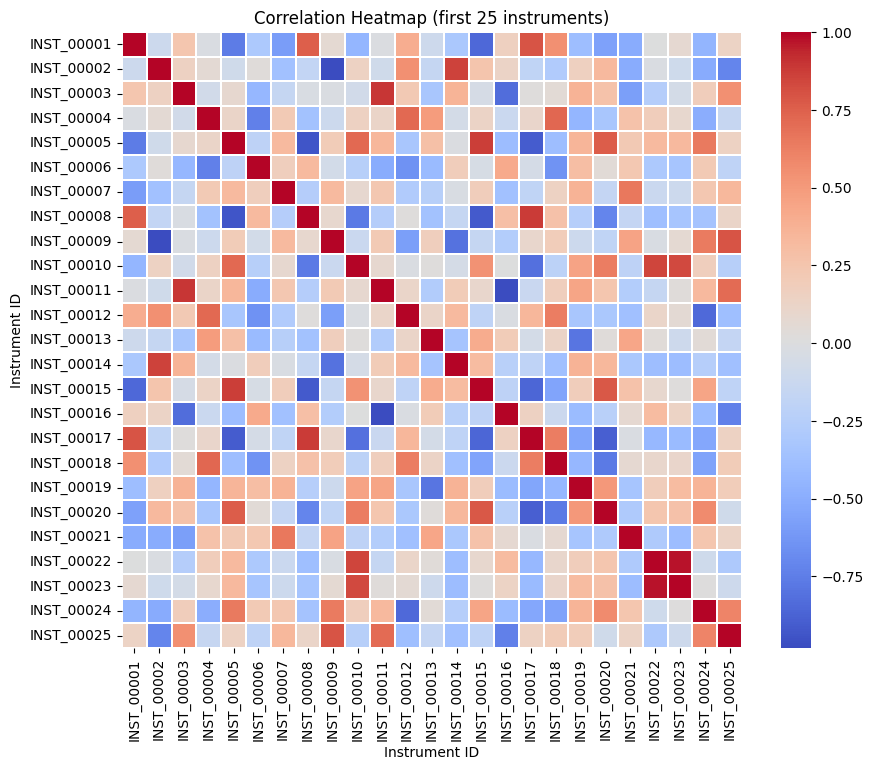

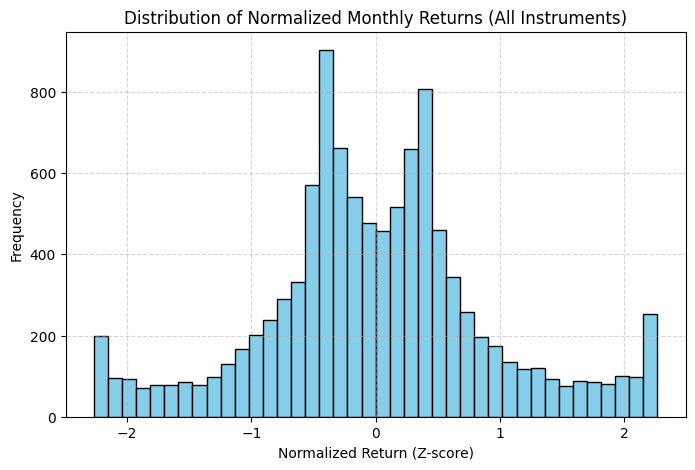

📈 Average pairwise correlation among instruments: -0.000


In [ ]:
# --- Step 6: Visualizing Cleaned and Normalized Data ---

import matplotlib.pyplot as plt
import seaborn as sns

# 1️⃣ Correlation Heatmap (subset for readability)
corr_matrix = returns_df.corr()
subset = corr_matrix.iloc[:25, :25]  # only first 25 for clarity

plt.figure(figsize=(10, 8))
sns.heatmap(subset, cmap="coolwarm", annot=False, linewidths=0.3)
plt.title("Correlation Heatmap (first 25 instruments)")
plt.xlabel("Instrument ID")
plt.ylabel("Instrument ID")
plt.show()

# 2️⃣ Distribution of normalized returns
plt.figure(figsize=(8, 5))
plt.hist(returns_df.values.flatten(), bins=40, color="skyblue", edgecolor="black")
plt.title("Distribution of Normalized Monthly Returns (All Instruments)")
plt.xlabel("Normalized Return (Z-score)")
plt.ylabel("Frequency")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# 3️⃣ Average Correlation Value
avg_corr = corr_matrix.where(~np.eye(corr_matrix.shape[0],dtype=bool)).mean().mean()
print(f"📈 Average pairwise correlation among instruments: {avg_corr:.3f}")

# Optional: Save visuals
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix.iloc[:50,:50], cmap='coolwarm')
plt.title("Correlation Heatmap (50 Instruments)")
plt.savefig("outputs/correlation_heatmap_50.png")
plt.close()


#Step 7 – Final Portfolio Optimization

Now that we have clean and normalized data, we perform the final portfolio optimization using two approaches:

Minimum Variance Portfolio (MVP) – minimizes total risk (volatility) regardless of return.
🔹 Ideal for risk-averse investors.

Maximum Sharpe Ratio Portfolio (MSP) – maximizes the return per unit of risk.
🔹 Ideal for balanced, high-performance portfolios.

Definitions:

Expected Return (μ): Average return the portfolio is expected to generate.
Example: If μ = 0.1 → expected return is 10%.

Volatility (σ): Risk or uncertainty of the portfolio, measured as standard deviation.
Example: σ = 0.2 → portfolio fluctuates ±20% around expected value.

Sharpe Ratio (S): Measures risk-adjusted performance = μ / σ.
Higher Sharpe ratio = better trade-off between risk and return.

After optimization, we’ll export:

🧮 Target Weights – how much to allocate to each instrument

💼 Trade Recommendations – what to buy/sell

📊 Risk–Return Report – key performance metrics

Each file will be saved in the /outputs folder and can be used for dashboards or risk analytics integration.

⚙️ Running final optimization for 1500 instruments...
✅ Saved final target weights and risk report in /outputs/


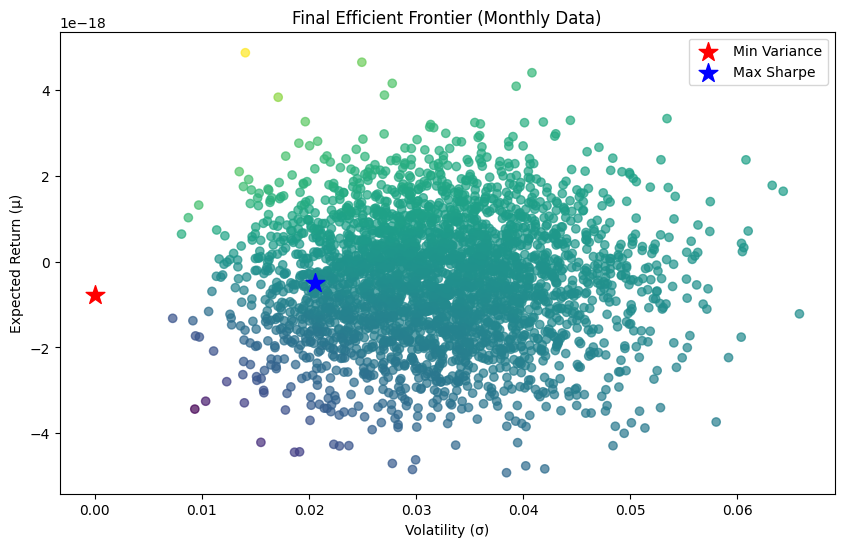

In [ ]:
from scipy.optimize import minimize
import os

# Ensure outputs directory
os.makedirs("outputs", exist_ok=True)

# Step 7: Portfolio Optimization on Cleaned Monthly Data
mean_returns = returns_df.mean()
cov_matrix = returns_df.cov()
assets = mean_returns.index.tolist()
num_assets = len(assets)

def portfolio_return(weights, mean_returns):
    return np.dot(weights, mean_returns)

def portfolio_volatility(weights, cov_matrix):
    return np.sqrt(np.dot(weights.T, np.dot(cov_matrix.values, weights)))

def negative_sharpe(weights, mean_returns, cov_matrix):
    ret = portfolio_return(weights, mean_returns)
    vol = portfolio_volatility(weights, cov_matrix)
    return -ret / vol if vol != 0 else 9999

# Constraints: sum(weights) = 1
constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
bounds = tuple((0, 0.2) for _ in range(num_assets))  # max 20% per instrument
initial_weights = np.array(num_assets * [1.0 / num_assets])

print(f"⚙️ Running final optimization for {num_assets} instruments...")

# Minimize variance (risk)
opt_min_var = minimize(portfolio_volatility, initial_weights,
                       args=(cov_matrix,),
                       method='SLSQP', bounds=bounds,
                       constraints=constraints)

# Maximize Sharpe ratio
opt_max_sharpe = minimize(negative_sharpe, initial_weights,
                          args=(mean_returns, cov_matrix),
                          method='SLSQP', bounds=bounds,
                          constraints=constraints)

# Extract weights
min_var_weights = opt_min_var.x
max_sharpe_weights = opt_max_sharpe.x

# Calculate metrics
min_var_ret = portfolio_return(min_var_weights, mean_returns)
min_var_vol = portfolio_volatility(min_var_weights, cov_matrix)
max_sharpe_ret = portfolio_return(max_sharpe_weights, mean_returns)
max_sharpe_vol = portfolio_volatility(max_sharpe_weights, cov_matrix)
sharpe_ratio = max_sharpe_ret / max_sharpe_vol

# Combine results into DataFrames
target_weights = pd.DataFrame({
    "Instrument_ID": assets,
    "Instrument_Name": instruments.set_index("instrument_id").loc[assets, "instrument_name"].values,
    "Target Weight (Min Variance)": min_var_weights,
    "Target Weight (Max Sharpe)": max_sharpe_weights
})

risk_report = pd.DataFrame({
    "Metric": ["Expected Return", "Volatility", "Sharpe Ratio"],
    "Min Variance Portfolio": [min_var_ret, min_var_vol, None],
    "Max Sharpe Portfolio": [max_sharpe_ret, max_sharpe_vol, sharpe_ratio]
})

# Save outputs
target_weights.to_csv("outputs/final_target_weights.csv", index=False)
risk_report.to_csv("outputs/final_risk_report.csv", index=False)

print("✅ Saved final target weights and risk report in /outputs/")

# --- Visualization: Final Efficient Frontier ---
returns_list = []
volatility_list = []
weights_list = []

for _ in range(3000):
    w = np.random.dirichlet(np.ones(num_assets), size=1)[0]
    returns_list.append(portfolio_return(w, mean_returns))
    volatility_list.append(portfolio_volatility(w, cov_matrix))
    weights_list.append(w)

plt.figure(figsize=(10,6))
plt.scatter(volatility_list, returns_list, c=np.array(returns_list)/np.array(volatility_list), cmap='viridis', alpha=0.7)
plt.scatter(min_var_vol, min_var_ret, c='red', marker='*', s=200, label='Min Variance')
plt.scatter(max_sharpe_vol, max_sharpe_ret, c='blue', marker='*', s=200, label='Max Sharpe')
plt.xlabel("Volatility (σ)")
plt.ylabel("Expected Return (μ)")
plt.title("Final Efficient Frontier (Monthly Data)")
plt.legend()
plt.show()


# Step 8 — Final Exports: Weekly & Monthly (Dashboard-ready)

This step:
- Cleans weekly & monthly returns (same rules as Step 5).
- Runs Min-Variance and Max-Sharpe optimizations for each period.
- Produces CSVs and plots that are ready for the dashboard.

Outputs (saved to `outputs/`):
- `optimized_weights_minvar_{period}.csv`
- `optimized_weights_maxsharpe_{period}.csv`
- `trade_recommendations_minvar_{period}.csv`
- `trade_recommendations_maxsharpe_{period}.csv`
- `risk_summary_{period}.csv`
- `top20_minvar_{period}.csv`, `top20_maxsharpe_{period}.csv`
- `efficient_frontier_{period}.png`, `allocation_pie_{period}.png`

Notes:
- Percent columns are in `%` (easier for business users).
- Action column: BUY if change positive, SELL if negative, HOLD otherwise.
- If optimizer fails for a period, code falls back to an equal-weight portfolio to keep outputs consistent.


In [ ]:
# ------------------ STEP 8: FINAL PORTFOLIO OUTPUTS (SELF-CONTAINED) ------------------

import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Ensure output folder
portfolio_folder = "portfolio_outputs"
os.makedirs(portfolio_folder, exist_ok=True)

# ------------------ Helper Functions ------------------

def clean_returns(df, min_non_null_ratio=0.5, clip_q=(0.01,0.99)):
    """Clean returns: drop sparse instruments, fill missing, clip outliers, z-score normalize."""
    df = df.copy()
    thresh = int(min_non_null_ratio * len(df))
    df = df.dropna(axis=1, thresh=thresh)
    df = df.fillna(df.median())
    loq, hiq = clip_q
    for col in df.columns:
        low, high = df[col].quantile([loq, hiq])
        df[col] = df[col].clip(low, high)
    df = (df - df.mean()) / df.std(ddof=0)
    return df

def optimize_portfolio(mean_ret, cov, max_weight=0.2):
    """Optimize portfolio for min variance and max Sharpe ratio."""
    n = len(mean_ret)
    x0 = np.ones(n) / n
    cons = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1})
    bnds = tuple((0.0, max_weight) for _ in range(n))

    def port_ret(w): return float(np.dot(w, mean_ret))
    def port_vol(w): return float(np.sqrt(np.dot(w.T, np.dot(cov.values, w))))
    def neg_sharpe(w):
        v = port_vol(w)
        if v <= 0: return 1e6
        return -port_ret(w)/v

    # Min variance
    res_min = minimize(lambda w: port_vol(w), x0, method='SLSQP', bounds=bnds, constraints=cons, options={'maxiter':1000})
    w_min = res_min.x if res_min.success else np.ones(n)/n
    w_min /= w_min.sum()

    # Max Sharpe
    res_sh = minimize(neg_sharpe, x0, method='SLSQP', bounds=bnds, constraints=cons, options={'maxiter':1000})
    w_sh = res_sh.x if res_sh.success else w_min.copy()

    metrics = {
        "minvar": {
            "weights": w_min,
            "expected_return": port_ret(w_min),
            "volatility": port_vol(w_min),
            "sharpe": port_ret(w_min)/port_vol(w_min)
        },
        "maxsh": {
            "weights": w_sh,
            "expected_return": port_ret(w_sh),
            "volatility": port_vol(w_sh),
            "sharpe": port_ret(w_sh)/port_vol(w_sh)
        }
    }
    return metrics


def save_outputs(period_label, returns_df, instruments_df, merged_df, n_sim=2000, max_weight=0.2):
    """Clean returns, optimize, and save all CSVs and plots for a given period."""
    print(f"\n--- Processing {period_label} ---")

    # 1️⃣ Clean returns
    cleaned = clean_returns(returns_df)
    mean_ret = cleaned.mean()
    cov = cleaned.cov()

    # 2️⃣ Match with instruments
    assets = [a for a in mean_ret.index if a in instruments_df["instrument_id"].values]
    mean_ret = mean_ret.reindex(assets)
    cov = cov.reindex(index=assets, columns=assets)

    # 3️⃣ Current weights
    if "portfolio_weight" in merged_df.columns:
        current_weights = merged_df.groupby("instrument_id")["portfolio_weight"].mean().reindex(assets).fillna(0)
    else:
        current_weights = pd.Series(0.0, index=assets)

    # 4️⃣ Optimize portfolios
    metrics = optimize_portfolio(mean_ret.values, cov, max_weight=max_weight)
    w_min = pd.Series(metrics["minvar"]["weights"], index=assets)
    w_max = pd.Series(metrics["maxsh"]["weights"], index=assets)

    # 5️⃣ Build tables
    inst_idx = instruments_df.set_index("instrument_id")
    def make_df(weights, strat):
        df = pd.DataFrame({
            "instrument_id": assets,
            "symbol": inst_idx.reindex(assets)["symbol"].values,
            "instrument_name": inst_idx.reindex(assets)["instrument_name"].values,
            "sector": inst_idx.reindex(assets)["sector"].values,
            "current_weight": current_weights.values,
            "target_weight": weights.values
        })
        df["change"] = df["target_weight"] - df["current_weight"]
        df["current_weight_pct"] = df["current_weight"]*100
        df["target_weight_pct"] = df["target_weight"]*100
        df["change_pct"] = df["change"]*100
        df["action"] = df["change"].apply(lambda x: "BUY" if x>1e-6 else ("SELL" if x<-1e-6 else "HOLD"))
        df["period"] = period_label
        df["strategy"] = strat
        return df

    df_min = make_df(w_min, "min_variance")
    df_max = make_df(w_max, "max_sharpe")

    # 6️⃣ Save CSVs
    df_min.to_csv(f"{portfolio_folder}/optimized_weights_minvar_{period_label}.csv", index=False)
    df_max.to_csv(f"{portfolio_folder}/optimized_weights_maxsharpe_{period_label}.csv", index=False)
    df_min.sort_values("target_weight", ascending=False).head(20).to_csv(f"{portfolio_folder}/top20_minvar_{period_label}.csv", index=False)
    df_max.sort_values("target_weight", ascending=False).head(20).to_csv(f"{portfolio_folder}/top20_maxsharpe_{period_label}.csv", index=False)

    # 7️⃣ Risk summary
    risk_df = pd.DataFrame({
        "period": [period_label, period_label],
        "strategy": ["min_variance", "max_sharpe"],
        "expected_return": [metrics["minvar"]["expected_return"], metrics["maxsh"]["expected_return"]],
        "expected_return_pct": [metrics["minvar"]["expected_return"]*100, metrics["maxsh"]["expected_return"]*100],
        "volatility": [metrics["minvar"]["volatility"], metrics["maxsh"]["volatility"]],
        "volatility_pct": [metrics["minvar"]["volatility"]*100, metrics["maxsh"]["volatility"]*100],
        "sharpe": [metrics["minvar"]["sharpe"], metrics["maxsh"]["sharpe"]]
    })
    risk_df.to_csv(f"{portfolio_folder}/risk_summary_{period_label}.csv", index=False)

    # 8️⃣ Efficient frontier
    n = len(assets)
    sim_r, sim_v, sim_s = [], [], []
    for _ in range(n_sim):
        w = np.random.rand(n)
        w /= w.sum()
        w = np.clip(w, 0, max_weight)
        if w.sum() == 0: continue
        w /= w.sum()
        r = float(np.dot(w, mean_ret.values))
        v = float(np.sqrt(np.dot(w.T, np.dot(cov.values, w))))
        sim_r.append(r); sim_v.append(v); sim_s.append(r/(v+1e-12))

    plt.figure(figsize=(10,6))
    sc = plt.scatter(sim_v, sim_r, c=sim_s, cmap='viridis', s=10, alpha=0.6)
    plt.scatter(metrics["minvar"]["volatility"], metrics["minvar"]["expected_return"], c='red', marker='*', s=180, label='Min Variance')
    plt.scatter(metrics["maxsh"]["volatility"], metrics["maxsh"]["expected_return"], c='blue', marker='*', s=180, label='Max Sharpe')
    plt.colorbar(sc, label='Sharpe Ratio')
    plt.xlabel("Volatility (σ)"); plt.ylabel("Expected Return (μ)")
    plt.title(f"Efficient Frontier ({period_label})")
    plt.legend(); plt.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.savefig(f"{portfolio_folder}/efficient_frontier_{period_label}.png", dpi=150)
    plt.close()

    # 9️⃣ Pie chart (top 10 Max Sharpe)
    top_alloc = df_max.sort_values("target_weight", ascending=False).head(10)
    plt.figure(figsize=(7,7))
    plt.pie(top_alloc["target_weight_pct"], labels=top_alloc["instrument_name"], autopct='%1.1f%%')
    plt.title(f"Top 10 Allocation by Target Weight (Max Sharpe) - {period_label}")
    plt.tight_layout()
    plt.savefig(f"{portfolio_folder}/allocation_pie_{period_label}.png", dpi=150)
    plt.close()

    print(f"✅ Saved CSVs and plots for {period_label} in '{portfolio_folder}/'")
    return {"df_min": df_min, "df_max": df_max, "risk_df": risk_df}


# ------------------ Execute for Both Periods ------------------

# Auto-clean and run both directly (no need for monthly_clean / weekly_clean)
res_monthly = save_outputs("monthly", monthly_returns, instruments, merged)
res_weekly  = save_outputs("weekly", weekly_returns, instruments, merged)

# Combine all risk summaries
combined_risks = pd.concat([res_monthly["risk_df"], res_weekly["risk_df"]], ignore_index=True)
combined_risks.to_csv(f"{portfolio_folder}/final_portfolio_summary.csv", index=False)
print(f"✅ Combined risk summary saved as '{portfolio_folder}/final_portfolio_summary.csv'")



--- Processing monthly ---
✅ Saved CSVs and plots for monthly in 'portfolio_outputs/'

--- Processing weekly ---
✅ Saved CSVs and plots for weekly in 'portfolio_outputs/'
✅ Combined risk summary saved as 'portfolio_outputs/final_portfolio_summary.csv'


In [ ]:
from google.colab import files
import shutil

# Zip the folder
shutil.make_archive("portfolio_outputs", "zip", "portfolio_outputs")

# Download
files.download("portfolio_outputs.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>